
<div style="background-color: lightgreen; color: black; padding: 20px; box-sizing: border-box; width: 99%;">

👋 <b>¡Hola! Soy Dot, tu revisor IA.</b>

🎉 <b>¡Felicidades! Has aprobado tu proyecto.</b>

¡Excelente trabajo en esta revisión! Corregiste los problemas de la ronda anterior: tu diagnóstico de participación cero (zero-share) ahora coincide con tus cálculos, y tus conclusiones sobre dispositivo, región y abandono están respaldadas por nueva evidencia (la razón de correlación y los boxplots) o se limitan a lo que realmente mediste. Para seguir creciendo, mantén tus etiquetas de intensidad consistentes con la escala que definiste y evita afirmaciones que requieran una prueba estadística que no has realizado. ¡Sigue con ese gran trabajo analítico!

Si experimentas alguna dificultad o error, no dudes en contactar a nuestro equipo de soporte haciendo clic en el ícono de chat en la esquina superior derecha o escribiéndonos a [helpme@tripleten.com](mailto:helpme@tripleten.com).

<hr style="margin-top: 20px; margin-bottom: 20px;">

<details>
<summary><b style="cursor: pointer;">💡 Haz clic aquí para ver cómo leer mis comentarios (Leyenda de colores)</b></summary>
<div style="margin-top: 15px;">
A continuación encontrarás mis comentarios. <b>Te pido amablemente que no los muevas, modifiques ni elimines</b>.

Puedes encontrar mis comentarios resaltados en recuadros verdes, amarillos o rojos como estos:

<div class="alert alert-block alert-success">
Éxito. Todo se ha realizado correctamente.
</div>

<div class="alert alert-block alert-warning">
Observaciones. Algunas recomendaciones.
</div>

<div class="alert alert-block alert-danger">
Por corregir. El bloque requiere algunas correcciones.
</div>
</div>
</details>

</div>


# Proyecto 7 - Explorando factores de comportamiento en NovaRetail+


NovaRetail+ es una plataforma de comercio electrónico en Latinoamérica con millones de usuarios.

Para el cierre de 2024, el equipo de **Crecimiento y retención** tiene como objetivo responder:

**¿Qué factores del comportamiento del cliente están más fuertemente asociados con el ingreso anual generado?**

> Este proyecto es un análisis **correlacional** (exploratorio).  
> **Correlación ≠ causalidad.**

## Sección 1 - Cargar y explorar el dataset

En esta sección validamos:
- que el dataset cargue correctamente
- tipos de datos
- valores faltantes / rangos generales

Antes de correlacionar, primero entendemos el “terreno”.

In [1]:
# Importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pointbiserialr, chi2_contingency


### Cargar Dataset

In [2]:
# Cargar el dataset y explorar datos
df = pd.read_csv("/datasets/novaretail_comportamiento_clientes_2024.csv")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  float64
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(5), int64(4), object(3)
memory usage: 1.4+ MB


<div class="alert alert-block alert-success">

Buen comienzo. Cargas el dataset desde la ruta correcta y ejecutas `df.info()` de inmediato. La salida confirma 15,000 filas, 12 columnas y ningún valor nulo, y muestra que `edad` está almacenada como `float64`. Esa observación guía tu posterior conversión de tipos.

</div>

#### Descripción del conjunto de datos

El dataset contiene las siguientes columnas:

- `id_cliente` — Identificador único del cliente.
- `edad` — Edad del cliente.
- `nivel_ingreso` — Ingreso anual estimado del cliente.
- `visitas_mes` — Número de visitas a la aplicación o sitio web durante el mes.
- `compras_mes` — Número de compras realizadas en el mes.
- `gasto_publicidad_dirigida` — Gasto en anuncios asignado al usuario.
- `satisfaccion` — Calificación de satisfacción del cliente en una escala del 1 al 5.
- `miembro_premium` — Indica si el cliente tiene suscripción premium (1) o no (0).
- `abandono` — Indica si el cliente abandonó la plataforma (1) o no (0).
- `tipo_dispositivo` — Tipo de dispositivo utilizado por el cliente (móvil, escritorio o tablet).
- `region` — Región geográfica del cliente (norte, sur, oeste o este).
- `ingreso_anual` — Ingreso anual generado por el cliente para la empresa.

La métrica principal de análisis es `ingreso_anual`, utilizada para evaluar el impacto económico de los clientes.


In [3]:
# mostrar las primeras 5 filas
df.head()


,id_cliente,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,tipo_dispositivo,region,ingreso_anual
0,CL-100000,44.0,28565.77,9,1,31.36,3.9,0,0,móvil,norte,23.22
1,CL-100001,36.0,29673.44,11,3,24.66,3.7,0,0,tablet,sur,93.47
2,CL-100002,46.0,30642.95,9,0,0.00,2.9,0,0,móvil,este,0.00
3,CL-100003,56.0,39468.61,8,0,6.81,3.1,0,0,móvil,este,0.00
4,CL-100004,35.0,22527.83,9,2,26.49,2.3,0,0,móvil,sur,33.76


## Sección 2 - Preparar datos y documentar supuestos

#### Exploración inicial de los datos
El conjunto de datos contiene **15,000 registros** y **12 columnas**, sin valores nulos.

**Variables numéricas**  
Se identifican las siguientes columnas numéricas:

* `edad`
* `nivel_ingreso`
* `visitas_mes`
* `compras_mes`
* `gasto_publicidad_dirigida`
* `satisfaccion`
* `ingreso_anual`

La mayoría de estas variables presentan tipos de datos adecuados.
La columna `edad` estaba como float, pero representa años completos, por lo que se convierte a entero.


**Variables binarias**  
Las siguientes columnas representan variables binarias:
- `miembro_premium`
- `abandono`

Ambas están codificadas como 0 y 1, **no requieren transformación adicional**.

**Variables categóricas**  
Se identifican las siguientes columnas categóricas:
- `id_cliente`
- `tipo_dispositivo`
- `region`

Estas variables están correctamente definidas y no requieren transformación adicional.

In [4]:
# Corregir el tipo de dato
print("Edades con decimales:", (df["edad"] % 1 != 0).sum())
df["edad"] = df["edad"].astype(int)


Edades con decimales: 0


In [5]:
# verificar cambios
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  int64  
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(4), int64(5), object(3)
memory usage: 1.4+ MB


#### Explorar variables numéricas

In [6]:
# Estadísticas descriptivas de variables numéricas
df.describe()


,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,ingreso_anual
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,38.262400,30019.704782,10.029000,1.206467,20.149301,3.603693,0.139267,0.150733,36.594180
std,11.492378,9833.166305,3.158189,1.105284,10.880724,0.685300,0.346236,0.357801,34.484888
min,18.000000,8000.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,30.000000,23127.097500,8.000000,0.000000,12.310000,3.100000,0.000000,0.000000,0.000000
50%,38.000000,30023.745000,10.000000,1.000000,19.730000,3.600000,0.000000,0.000000,30.705000
75%,46.000000,36768.440000,12.000000,2.000000,27.292500,4.100000,0.000000,0.000000,58.220000
max,75.000000,74790.840000,25.000000,8.000000,75.510000,5.000000,1.000000,1.000000,244.690000


In [7]:
# Proporción de ceros por columna numérica (%)
columnas_numericas_df = ["edad", "nivel_ingreso", "visitas_mes", "compras_mes",
                         "gasto_publicidad_dirigida", "satisfaccion", "ingreso_anual"]
print((df[columnas_numericas_df] == 0).mean().mul(100).round(1))

print("\n% de clientes con ingreso_anual = 0:",
      round((df["ingreso_anual"] == 0).mean() * 100, 1))
print("% de clientes con compras_mes = 0 que tienen ingreso_anual = 0:",
      round((df.loc[df["compras_mes"] == 0, "ingreso_anual"] == 0).mean() * 100, 1))
print("% de clientes con ingreso_anual = 0 que tienen compras_mes = 0:",
      round((df.loc[df["ingreso_anual"] == 0, "compras_mes"] == 0).mean() * 100, 1))

edad                          0.0
nivel_ingreso                 0.0
visitas_mes                   0.0
compras_mes                  30.4
gasto_publicidad_dirigida     3.0
satisfaccion                  0.0
ingreso_anual                30.4
dtype: float64

% de clientes con ingreso_anual = 0: 30.4
% de clientes con compras_mes = 0 que tienen ingreso_anual = 0: 100.0
% de clientes con ingreso_anual = 0 que tienen compras_mes = 0: 100.0


**Diagnóstico inicial de variables numéricas**

* `edad` — Va de 18 a 75 años, con media (38.3) y mediana (38) casi iguales: distribución aproximadamente simétrica, sin ceros y sin valores imposibles.
* `nivel_ingreso` — Mínimo de 8,000 exacto (posible piso del dataset) y máximo de 74,790. Media (30,020) y mediana (30,024) casi idénticas, con una cola larga a la derecha. Sin ceros.
* `visitas_mes` — Rango de 1 a 25 visitas, media y mediana en 10. El máximo (25) queda muy por encima del 75% (12), una cola derecha por revisar en los outliers. Sin ceros.
* `compras_mes` — Va de 0 a 8 y es una variable discreta. El 30.4% de los clientes no hizo ninguna compra en el mes (el primer cuartil de `describe()` vale 0 porque al menos una cuarta parte son ceros, pero la proporción exacta es 30.4%). La mediana es 1.
* `gasto_publicidad_dirigida` — Va de 0 a 75.5, con media (20.1) y mediana (19.7) similares. El 3.0% de los clientes tiene gasto 0 (sin gasto asignado) y el máximo es bastante alto frente al 75% (27.3).
* `satisfaccion` — Se mantiene dentro de la escala válida de 1 a 5, con media y mediana de 3.6. Sin ceros.
* `ingreso_anual` (variable foco) — El 30.4% de los clientes tiene ingreso igual a 0. La media (36.6) supera a la mediana (30.7) y el máximo (244.7) está muy lejos del 75% (58.2): distribución sesgada a la derecha con muchos ceros. Su escala es muy distinta a la de `nivel_ingreso`, así que se asume que son métricas diferentes.

**Ceros en `compras_mes` e `ingreso_anual`:** ambos tienen exactamente la misma proporción (30.4%). Se verificó que el 100% de los clientes con 0 compras tiene ingreso 0, y que el 100% de los clientes con ingreso 0 tiene 0 compras: son los mismos clientes. Se consideran valores válidos (clientes sin actividad de compra) y no errores de captura, por lo que se conservan.

No hay valores nulos ni rangos imposibles, por lo que no se eliminan registros.

<div class="alert alert-block alert-success">

Corregiste bien el problema anterior. Ahora indicas que el 30.4% de los clientes no realizó compras. También explicas que un primer cuartil de 0 solo significa que al menos una cuarta parte de los valores son cero, y esto coincide con tu propio cálculo de la proporción de ceros. Tu diagnóstico ofrece una observación concreta para cada columna numérica. Comprobar que las compras en cero y los ingresos en cero corresponden a los mismos clientes respalda tu decisión de conservar esos ceros.

</div>

#### Explorar variables binarias

In [8]:
# Verificar que cada columna tenga únicamente dos valores posibles
columnas_binarias = ["miembro_premium", "abandono"]
print(df[columnas_binarias].nunique())
print()
for col in columnas_binarias:
    print(df[col].value_counts(normalize=True) * 100)
    print()


miembro_premium    2
abandono           2
dtype: int64

0    86.073333
1    13.926667
Name: miembro_premium, dtype: float64

0    84.926667
1    15.073333
Name: abandono, dtype: float64



**Diagnóstico inicial de variables binarias**

* `miembro_premium` — Solo toma los valores 0 y 1. El 13.9% de los clientes es premium y el 86.1% no lo es.
* `abandono` — Solo toma los valores 0 y 1. El 15.1% de los clientes abandonó la plataforma y el 84.9% no.

Ambas están correctamente codificadas, sin valores inesperados. Los grupos están desbalanceados (aproximadamente 1 de cada 7 clientes en el grupo 1), por lo que los coeficientes punto-biserial se interpretarán considerando ese desbalance.

#### Explorar variables categóricas

In [9]:
# Verificar el número de valores únicos por variable categórica
columnas_categoricas = ["id_cliente", "tipo_dispositivo", "region"]
print(df[columnas_categoricas].nunique())
print("\nIDs duplicados:", df["id_cliente"].duplicated().sum())


id_cliente          15000
tipo_dispositivo        3
region                  4
dtype: int64

IDs duplicados: 0


In [10]:
# Explorar variables categóricas y cómo se distribuyen
for col in ["tipo_dispositivo", "region"]:
    print(df[col].value_counts(normalize=True) * 100)
    print()

móvil         65.453333
escritorio    24.800000
tablet         9.746667
Name: tipo_dispositivo, dtype: float64

norte    29.30
oeste    25.40
sur      24.84
este     20.46
Name: region, dtype: float64



In [11]:
print((df.loc[df["ingreso_anual"] == 0, "compras_mes"] == 0).mean() * 100)

100.0


<div class="alert alert-block alert-warning">

Limpieza opcional: esta verificación repite una que ya hiciste, con etiquetas claras, en tu cálculo de zero-share. Imprime un `100.0` sin ninguna etiqueta, y está ubicada entre la exploración categórica y su diagnóstico. Yo la eliminaría. Si decides conservarla, agrega una etiqueta breve al `print` y una frase que explique por qué está ahí.

</div>

**Diagnóstico inicial de variables categóricas**

* `tipo_dispositivo` — Tiene 3 categorías: móvil (65.5%), escritorio (24.8%) y tablet (9.7%). Domina el móvil y tablet es el grupo más pequeño, aunque con volumen suficiente para comparar.
* `region` — Tiene 4 categorías bastante balanceadas: norte (29.3%), oeste (25.4%), sur (24.8%) y este (20.5%).
* `id_cliente` — Tiene 15,000 valores únicos y 0 duplicados. Es solo un identificador, por lo que no se incluirá en las correlaciones.

No hay categorías mal escritas ni valores inconsistentes.

### Supuestos

* `ingreso_anual` es la variable de interés del análisis.
* `id_cliente` es solo un identificador y se excluye de las correlaciones.
* Los ceros en `ingreso_anual` y `compras_mes` son valores válidos (clientes sin compras) y se conservan.
* Los valores atípicos (outliers) no se eliminan, porque los valores extremos parecen plausibles.
* `nivel_ingreso` (ingreso estimado del cliente) e `ingreso_anual` (ingreso generado para la empresa) se tratan como métricas distintas.
* El análisis utiliza todo el conjunto de datos disponible.
* Se utilizan distintos coeficientes según el tipo de variable:
  * **Pearson** asume relaciones lineales entre variables numéricas.
  * **Spearman** evalúa relaciones monótonas y no requiere normalidad.
  * **Punto biserial** se usa para relaciones numérica-binaria.
  * **V de Cramér** se usa para asociaciones entre variables categóricas.
* **Escala de interpretación** (valor absoluto del coeficiente, usada en todo el notebook): menor a 0.10 prácticamente nula; de 0.10 a 0.50 débil; de 0.50 a 0.80 moderada; 0.80 o más fuerte. Se señala posible colinealidad a partir de 0.85.

**Supuesto central:**
Este análisis identifica relaciones entre variables o segmentos, pero no prueba causalidad.

<div class="alert alert-block alert-success">

Tus supuestos ahora están mucho más completos. Cubren `ingreso_anual` como la variable de interés, la exclusión de `id_cliente`, los ceros siendo válidos y conservados, los valores atípicos (outliers) que no se eliminan, `nivel_ingreso` e `ingreso_anual` como métricas diferentes, y el umbral de colinealidad de 0.85. La escala de interpretación explícita es especialmente útil porque facilita aplicar las etiquetas de intensidad de manera consistente.

</div>

## Sección 3 - Visualización de relaciones

Observamos cómo se relacionan las variables numéricas.

### Heatmap

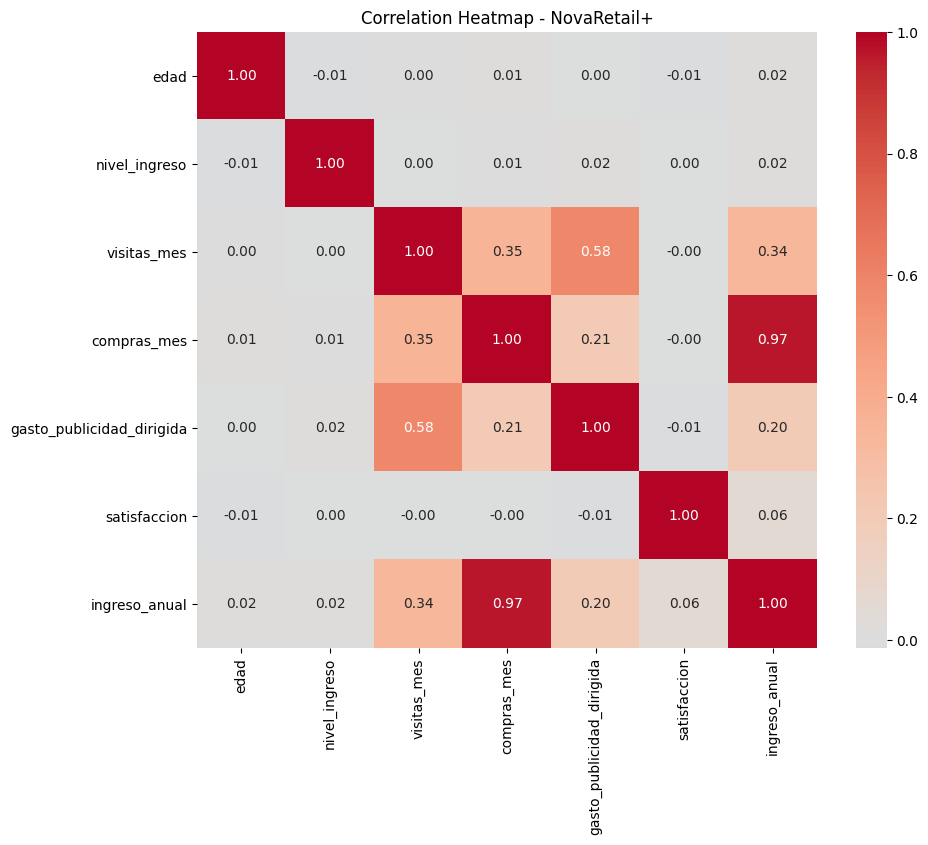

In [12]:
# Visualizar la matriz de correlación para identificar relaciones
columnas_numericas = ["edad", "nivel_ingreso", "visitas_mes", "compras_mes",
                      "gasto_publicidad_dirigida", "satisfaccion", "ingreso_anual"]

corr = df[columnas_numericas].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap - NovaRetail+")
plt.show()

<div class="alert alert-block alert-success">

Buen heatmap. Seleccionaste solo las variables numéricas relevantes, y `annot=True`, `fmt='.2f'` y `center=0` lo hacen fácil de leer. La figura muestra lo que describes: `edad`, `nivel_ingreso` y `satisfaccion` forman un bloque neutro. Las relaciones destacadas son `compras_mes`–`ingreso_anual` (0.97), `visitas_mes`–`gasto_publicidad_dirigida` (0.58) y `visitas_mes`–`ingreso_anual` (0.34).

</div>

In [13]:
# Correlación de cada variable con ingreso_anual (ordenada)
print(corr["ingreso_anual"].sort_values(ascending=False))

ingreso_anual                1.000000
compras_mes                  0.967149
visitas_mes                  0.337147
gasto_publicidad_dirigida    0.197483
satisfaccion                 0.056171
edad                         0.017496
nivel_ingreso                0.017446
Name: ingreso_anual, dtype: float64


**Observaciones generales (Heatmap)**

* Se observa que la mayoría de las variables prácticamente no se relacionan entre sí: `edad`, `nivel_ingreso` y `satisfaccion` tienen correlaciones de entre -0.01 y 0.02 con casi todas las demás.
* Las relaciones relevantes se concentran en un grupo de variables de comportamiento: `visitas_mes` y `gasto_publicidad_dirigida` (0.58, moderada), `visitas_mes` y `compras_mes` (0.35, débil a moderada) y `compras_mes` e `ingreso_anual` (0.97, muy fuerte).
* No hay correlaciones negativas relevantes.

**Observaciones respecto a `ingreso_anual`**

* Presenta una correlación muy fuerte con `compras_mes` (0.97). Es una relación esperable y casi mecánica: todos los clientes sin compras tienen ingreso 0. Esto sugiere posible colinealidad y no se interpretará como un hallazgo sorprendente.
* Presenta una correlación débil a moderada con `visitas_mes` (0.34). Como `visitas_mes` también se relaciona con `compras_mes` (0.35), esta asociación podría ser indirecta.
* Presenta una correlación débil con `gasto_publicidad_dirigida` (0.20).
* `satisfaccion` (0.06), `edad` (0.02) y `nivel_ingreso` (0.02) tienen relaciones prácticamente nulas con el ingreso generado.

<div class="alert alert-block alert-warning">

Tu lectura del mapa de calor es acertada y responsablemente no causal. Sin embargo, algunas etiquetas de fuerza no siguen la escala que definiste en tus supuestos. `visitas_mes` vs `compras_mes` (0.35) y `visitas_mes` vs `ingreso_anual` (0.34) se describen como 'débil a moderada', pero según tu escala ambas son débiles ('débil'), como ya indican tus secciones posteriores. 'Muy fuerte' (0.97) no es un nivel de tu escala, que termina en 'fuerte'. Agrega ese nivel a la escala o usa 'fuerte', aquí y en tus interpretaciones posteriores.

</div>

### Scatterplot general

No se incluye un scatterplot general (pairplot). El heatmap muestra que 3 de las 7 variables numéricas (`edad`, `nivel_ingreso` y `satisfaccion`) no tienen relación con las demás y que las asociaciones relevantes se concentran en pocos pares. Graficar las 49 combinaciones sobre 15,000 registros sería lento y poco informativo, por lo que los scatterplots se limitan a los pares con relaciones moderadas o fuertes (sección 3.3).

### Scatterplot para pares clave

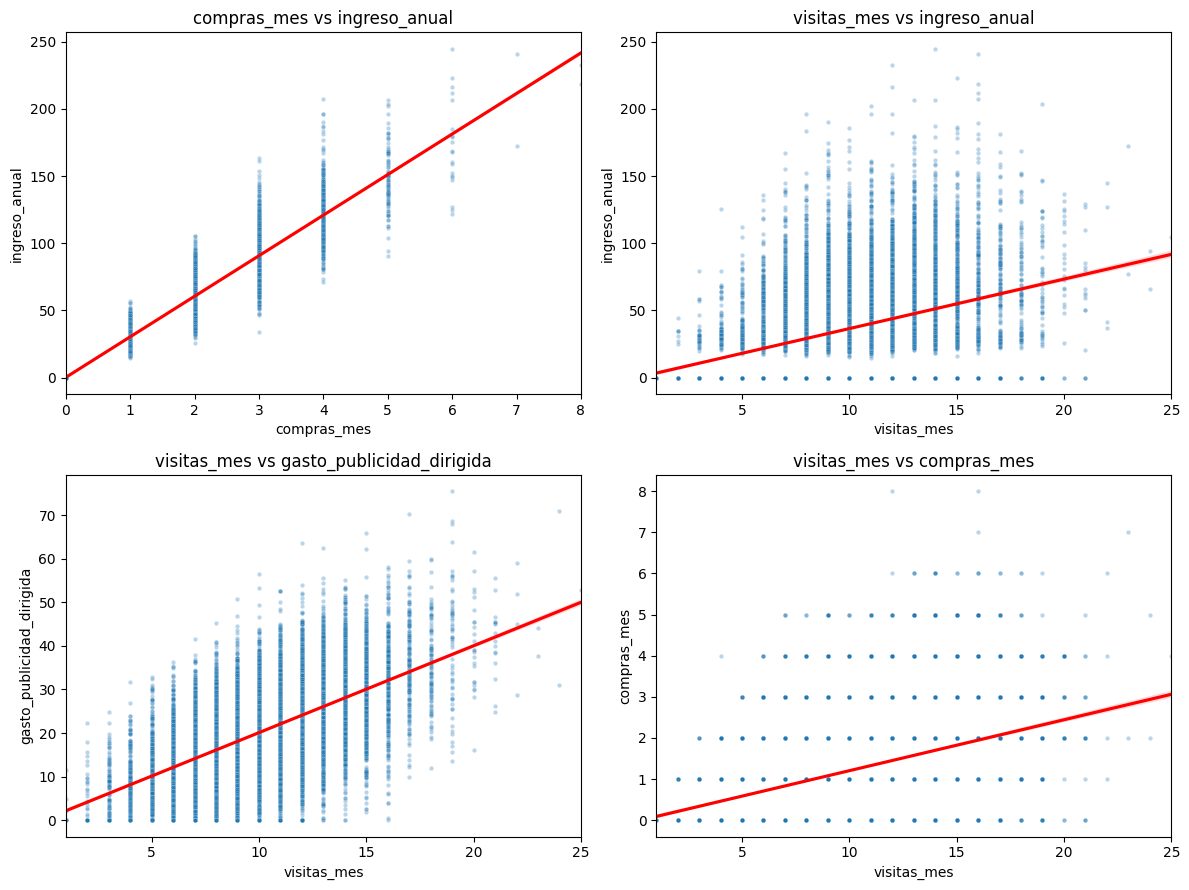

In [14]:
# Visualizar pares de variables con relaciones moderadas o fuertes
pares = [
    ("compras_mes", "ingreso_anual"),
    ("visitas_mes", "ingreso_anual"),
    ("visitas_mes", "gasto_publicidad_dirigida"),
    ("visitas_mes", "compras_mes"),
]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, (x, y) in zip(axes.flatten(), pares):
    sns.scatterplot(data=df, x=x, y=y, alpha=0.3, s=10, ax=ax)
    sns.regplot(data=df, x=x, y=y, scatter=False, color="red", ax=ax)
    ax.set_title(f"{x} vs {y}")

plt.tight_layout()
plt.show()

<div class="alert alert-block alert-success">

Cuadrícula de 2×2 limpia con pares de variables clave y un título en cada panel. `alpha=0.3` y `s=10` manejan bien el overplotting, y la línea de tendencia roja de `regplot` se dibuja sin duplicar los puntos. La figura muestra las franjas verticales de las variables discretas, la fila de ceros en income y la forma de abanico en el panel de ad-spend, lo que respalda tus observaciones escritas.

</div>

**Observaciones iniciales (Scatterplot)**

**compras_mes vs ingreso_anual**

* Dirección: positiva. A más compras en el mes, mayor ingreso anual.
* Dispersión: baja a media. Los puntos siguen de cerca la línea de tendencia (correlación 0.97), aunque la dispersión vertical dentro de cada nivel de compras aumenta a medida que crecen las compras.
* Outliers: hay pocos puntos en 6 y 7 compras, y algunos ingresos por encima de 200, pero siguen la tendencia general.
* Posible colinealidad: sí. La relación es casi mecánica (sin compras el ingreso es 0, y cada compra suma ingreso), por lo que ambas variables aportan casi la misma información y no se interpreta como un hallazgo sorprendente.

**visitas_mes vs ingreso_anual**

* Dirección: positiva, pero débil (correlación 0.34); la pendiente de la línea es suave.
* Dispersión: alta. Para un mismo número de visitas el ingreso varía de 0 a más de 200. Se ve una fila de puntos en `ingreso_anual = 0` en todos los niveles de visitas, que corresponden a clientes sin compras y que debilitan la relación.
* Outliers: pocos puntos con ingresos cercanos a 240 y unos cuantos con visitas por encima de 20.
* Posible colinealidad: no. La relación es moderada y podría ser indirecta, a través de `compras_mes`.

**visitas_mes vs gasto_publicidad_dirigida**

* Dirección: positiva y moderada (correlación 0.58).
* Dispersión: media a alta. El gasto mínimo es cercano a 0 en todos los niveles de visitas, pero el máximo sube a medida que aumentan las visitas, con una forma de abanico.
* Outliers: pocos puntos con gasto por encima de 60.
* Posible colinealidad: no, porque está por debajo de 0.85. Se debe evitar concluir que la publicidad genera visitas: la empresa podría estar asignando más anuncios a los clientes más activos (causalidad inversa).

**visitas_mes vs compras_mes**

* Dirección: positiva y débil (correlación 0.35).
* Dispersión: alta. `compras_mes` es discreta (0 a 8) y para cada número de visitas hay clientes con compras muy distintas.
* Outliers: pocos clientes con 6 a 8 compras.
* Posible colinealidad: no.

<div class="alert alert-block alert-warning">

Esta es una lectura minuciosa de los diagramas de dispersión. Cada par abarca dirección, dispersión, valores atípicos y colinealidad, y los detalles coinciden con la figura. Hay una inconsistencia. Para `visitas_mes vs ingreso_anual` dices correctamente que la relación es 'débil' (0.34) en el punto sobre la dirección, pero el punto sobre la colinealidad la llama 'moderada'. Según tu propia escala, 0.34 es débil, por lo que cambiar 'moderada' por 'débil' mantendría las etiquetas consistentes.

</div>

## Sección 4 - Coeficientes de correlación y evidencia numérica

En esta sección, se reportan coeficientes que respaldan los patrones
observados visualmente, utilizando el método adecuado según el tipo
de variables.

### Pearson / Spearman

In [15]:
# Calcular correlación entre variables relevantes (Pearson)
pares = [
    ("compras_mes", "ingreso_anual"),
    ("visitas_mes", "ingreso_anual"),
    ("gasto_publicidad_dirigida", "ingreso_anual"),
    ("visitas_mes", "gasto_publicidad_dirigida"),
    ("visitas_mes", "compras_mes"),
]

for x, y in pares:
    coef = df[x].corr(df[y], method="pearson")
    print(f"Pearson: {x} vs {y}: {coef:.4f}")

Pearson: compras_mes vs ingreso_anual: 0.9671
Pearson: visitas_mes vs ingreso_anual: 0.3371
Pearson: gasto_publicidad_dirigida vs ingreso_anual: 0.1975
Pearson: visitas_mes vs gasto_publicidad_dirigida: 0.5789
Pearson: visitas_mes vs compras_mes: 0.3538


In [16]:
# Calcular correlación entre variables relevantes (Spearman)
for x, y in pares:
    coef = df[x].corr(df[y], method="spearman")
    print(f"Spearman: {x} vs {y}: {coef:.4f}")

Spearman: compras_mes vs ingreso_anual: 0.9675
Spearman: visitas_mes vs ingreso_anual: 0.3210
Spearman: gasto_publicidad_dirigida vs ingreso_anual: 0.1850
Spearman: visitas_mes vs gasto_publicidad_dirigida: 0.5593
Spearman: visitas_mes vs compras_mes: 0.3329


**Observaciones de correlación**

**compras_mes vs ingreso_anual**

* Correlación positiva y muy fuerte: Pearson 0.967 y Spearman 0.968, prácticamente idénticos.
* Supera el umbral de 0.85, por lo que existe posible colinealidad: ambas variables aportan casi la misma información (sin compras no hay ingreso). Es una relación esperada, no un hallazgo sorprendente.

**visitas_mes vs ingreso_anual**

* Correlación positiva y débil: Pearson 0.337 y Spearman 0.321.
* Más visitas se asocian con algo más de ingreso, pero la fuerza es limitada. Como `visitas_mes` también se asocia con `compras_mes`, esta relación podría ser en parte indirecta.

**gasto_publicidad_dirigida vs ingreso_anual**

* Correlación positiva y débil: Pearson 0.198 y Spearman 0.185.
* El gasto publicitario explica poco del ingreso por sí solo. Esta relación también podría ser indirecta, ya que el gasto se asocia con las visitas y las visitas con las compras.

**visitas_mes vs gasto_publicidad_dirigida**

* Correlación positiva y moderada: Pearson 0.579 y Spearman 0.559.
* Es la relación más fuerte entre variables de comportamiento, sin llegar a colinealidad. No se interpreta como que la publicidad genera visitas: podría asignarse más gasto a los clientes más activos (causalidad inversa).

**visitas_mes vs compras_mes**

* Correlación positiva y débil: Pearson 0.354 y Spearman 0.333.
* Más visitas se asocian con algo más de compras, pero la relación es limitada.

En todos los pares, Pearson y Spearman difieren en menos de 0.03, por lo que ambas medidas coinciden y las conclusiones sobre la dirección y la intensidad son estables. Esto no confirma que las relaciones sean de línea recta: los scatterplots muestran una forma de abanico y una fila de clientes con ingreso 0, que podrían estar reduciendo los coeficientes.

<div class="alert alert-block alert-success">

Revisaste bien esta interpretación. Las etiquetas de fuerza ahora siguen tu escala: 0.337, 0.198 y 0.354 son débiles, y 0.579 es moderada. Tu párrafo final también es más preciso. Que Pearson y Spearman coincidan significa que las conclusiones sobre la dirección y la fuerza son estables, pero esto no demuestra relaciones lineales, ya que la forma de abanico y la fila con ingreso cero pueden estar reduciendo los coeficientes. También señalas los posibles vínculos indirectos y mantienes la advertencia de causalidad inversa para el gasto en publicidad.

</div>

### Punto-biserial

In [17]:
# Calcular correlación entre variables relevantes (punto-biserial)
columnas_binarias = ["miembro_premium", "abandono"]
columnas_numericas = ["ingreso_anual", "compras_mes", "visitas_mes",
                      "gasto_publicidad_dirigida", "satisfaccion"]

for col_bin in columnas_binarias:
    for col_num in columnas_numericas:
        coef, p_value = pointbiserialr(df[col_bin], df[col_num])
        print(f"Point-Biserial: {col_bin} vs {col_num}: {coef:.4f}")
    print()

Point-Biserial: miembro_premium vs ingreso_anual: 0.0931
Point-Biserial: miembro_premium vs compras_mes: 0.0034
Point-Biserial: miembro_premium vs visitas_mes: -0.0127
Point-Biserial: miembro_premium vs gasto_publicidad_dirigida: 0.0027
Point-Biserial: miembro_premium vs satisfaccion: 0.0257

Point-Biserial: abandono vs ingreso_anual: -0.0028
Point-Biserial: abandono vs compras_mes: 0.0083
Point-Biserial: abandono vs visitas_mes: -0.0089
Point-Biserial: abandono vs gasto_publicidad_dirigida: -0.0046
Point-Biserial: abandono vs satisfaccion: -0.0238



**Observaciones Punto-biserial**

**miembro_premium vs ingreso_anual**

* Relación positiva prácticamente nula (0.093, por debajo de 0.10): los clientes premium tienen un ingreso anual ligeramente mayor, pero la diferencia entre premium y no premium es mínima y no justifica decisiones por sí sola.

**miembro_premium vs el resto de variables evaluadas**

* Relaciones prácticamente nulas (entre -0.013 y 0.026) con `compras_mes`, `visitas_mes`, `gasto_publicidad_dirigida` y `satisfaccion`. Ser premium no distingue el comportamiento de los clientes en estas variables.

**abandono vs ingreso_anual**

* Relación prácticamente nula (-0.003): los clientes que abandonan generan un ingreso similar a los que se quedan.

**abandono vs el resto de variables evaluadas**

* Relaciones prácticamente nulas (entre -0.024 y 0.008) con `compras_mes`, `visitas_mes`, `gasto_publicidad_dirigida` y `satisfaccion`. Ninguna de las cinco variables numéricas evaluadas (`ingreso_anual`, `compras_mes`, `visitas_mes`, `gasto_publicidad_dirigida` y `satisfaccion`) se asocia con el abandono. `edad` y `nivel_ingreso` no se evaluaron contra `abandono` ni contra `miembro_premium`.

Los grupos están desbalanceados (13.9% premium y 15.1% abandono), pero ninguna relación alcanza siquiera el rango débil (0.10), por lo que el desbalance no cambia la conclusión.

<div class="alert alert-block alert-success">

Corregiste la extralimitación de antes. La conclusión sobre `abandono` ahora se limita a las cinco variables numéricas que probaste, las cuales nombras. También indicas que `edad` y `nivel_ingreso` no fueron evaluadas frente a `abandono` ni a `miembro_premium`. Los rangos que citas coinciden con la salida, y llamar 0.093 'prácticamente nula' es coherente con tu escala. Si quieres eliminar por completo esa salvedad, podrías añadir esas dos variables al cálculo de la correlación biserial puntual.

</div>

### V de Cramér

In [18]:
# Función para calcular V de Cramér
def cramer_v(df, col1, col2):
    # tabla de contingencia
    tabla = pd.crosstab(df[col1], df[col2])

    # calcular chi-cuadrado
    chi2, p_value, dof, expected = chi2_contingency(tabla)

    # calcular coeficiente V de Cramér
    n = tabla.values.sum()
    v = np.sqrt(chi2 / (n * (min(tabla.shape) - 1)))

    return v

In [20]:
# Aplicar V de Cramér en variables relevantes
pares_categoricos = [
    ("tipo_dispositivo", "region"),
    ("tipo_dispositivo", "miembro_premium"),
    ("tipo_dispositivo", "abandono"),
    ("region", "miembro_premium"),
    ("region", "abandono"),
    ("miembro_premium", "abandono"),
]

for c1, c2 in pares_categoricos:
    print(f"V de Cramér: {c1} vs {c2}: {cramer_v(df, c1, c2):.4f}")

V de Cramér: tipo_dispositivo vs region: 0.0124
V de Cramér: tipo_dispositivo vs miembro_premium: 0.0197
V de Cramér: tipo_dispositivo vs abandono: 0.0072
V de Cramér: region vs miembro_premium: 0.0126
V de Cramér: region vs abandono: 0.0154
V de Cramér: miembro_premium vs abandono: 0.1202


In [21]:
# Función: razón de correlación (eta), mide qué tanto cambia una variable numérica entre grupos
def razon_correlacion(df, col_categorica, col_numerica):
    grupos = df.groupby(col_categorica)[col_numerica]
    media_global = df[col_numerica].mean()
    ss_entre = (grupos.count() * (grupos.mean() - media_global) ** 2).sum()
    ss_total = ((df[col_numerica] - media_global) ** 2).sum()
    return np.sqrt(ss_entre / ss_total)

# Ingreso anual por grupo y razón de correlación
for col in ["tipo_dispositivo", "region", "miembro_premium", "abandono"]:
    print(df.groupby(col)["ingreso_anual"].agg(["count", "mean", "median"]).round(2))
    print(f"Razón de correlación ({col} vs ingreso_anual): {razon_correlacion(df, col, 'ingreso_anual'):.4f}\n")

                  count   mean  median
tipo_dispositivo                      
escritorio         3720  36.42   30.44
móvil              9818  36.59   30.69
tablet             1462  37.07   31.34
Razón de correlación (tipo_dispositivo vs ingreso_anual): 0.0049

        count   mean  median
region                      
este     3069  36.89   30.78
norte    4395  36.71   30.72
oeste    3810  35.72   30.36
sur      3726  37.10   30.94
Razón de correlación (region vs ingreso_anual): 0.0154

                 count   mean  median
miembro_premium                      
0                12911  35.30   29.95
1                 2089  44.58   37.70
Razón de correlación (miembro_premium vs ingreso_anual): 0.0931

          count   mean  median
abandono                      
0         12739  36.64   30.69
1          2261  36.36   30.72
Razón de correlación (abandono vs ingreso_anual): 0.0028



<div class="alert alert-block alert-success">

Cerraste la principal brecha del análisis. La razón de correlación (η) relaciona `tipo_dispositivo`, `region`, `miembro_premium` y `abandono` con `ingreso_anual`, y la función está implementada correctamente. El conteo, la media y la mediana por grupo aportan un contexto útil para cada coeficiente. Tus valores de η para las dos variables binarias coinciden con los resultados de la correlación punto-biserial, lo cual es una buena verificación cruzada.

</div>

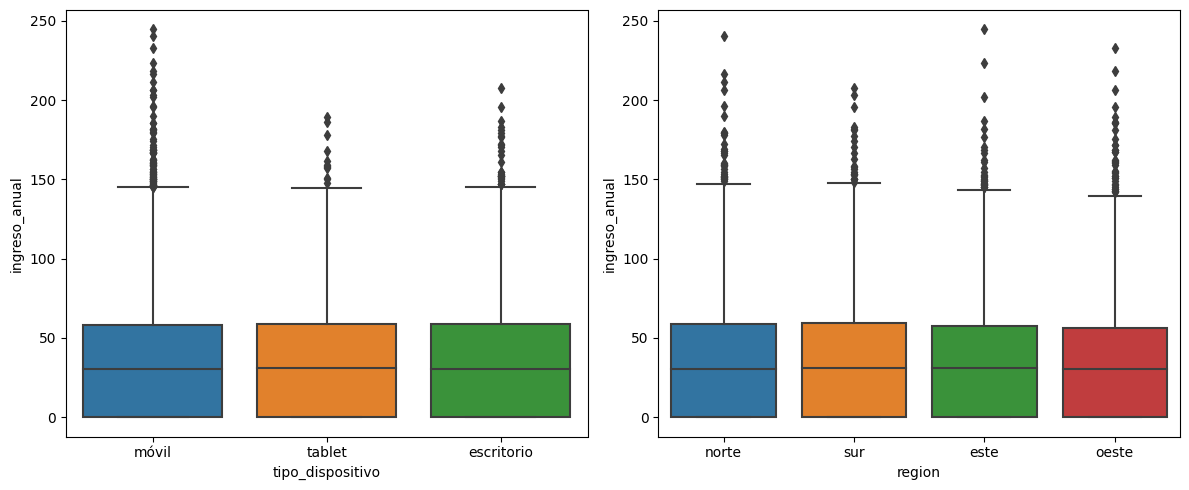

In [22]:
# Distribución del ingreso anual por dispositivo y región
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.boxplot(data=df, x="tipo_dispositivo", y="ingreso_anual", ax=axes[0])
sns.boxplot(data=df, x="region", y="ingreso_anual", ax=axes[1])
plt.tight_layout()
plt.show()

**Observaciones V de Cramér**

* Cinco de los seis pares tienen una asociación prácticamente nula (por debajo de 0.10):
  * `tipo_dispositivo` vs `region`: 0.012
  * `tipo_dispositivo` vs `miembro_premium`: 0.020
  * `tipo_dispositivo` vs `abandono`: 0.007
  * `region` vs `miembro_premium`: 0.013
  * `region` vs `abandono`: 0.015
* `miembro_premium` vs `abandono` es el único par con una asociación débil (0.120): ser premium y abandonar la plataforma no son independientes. La V de Cramér no indica la dirección (si los premium abandonan más o menos), solo la fuerza de la asociación.
* Estos cálculos solo comparan variables categóricas entre sí. No dicen nada sobre su relación con `ingreso_anual`, que se analiza en la siguiente subsección.


<div class="alert alert-block alert-warning">

Tu lectura es clara. Señalas que la V de Cramér solo compara variables categóricas entre sí y que indica la fuerza de la asociación, pero no su dirección. Una afirmación va más allá de lo que calculaste: decir que la membresía premium y el abandono 'no son independientes' implica una prueba de hipótesis, pero no ejecutaste ninguna. Puedes reportar el valor p de chi-cuadrado que tu función ya calcula, o suavizar la frase a 'muestran una asociación débil'. El cálculo de la razón de correlación y los boxplots también aparecen bajo este encabezado de V de Cramér, así que un subencabezado breve antes de ellos dejaría claro que responden a una pregunta distinta.

</div>

**Observaciones: variables categóricas vs ingreso_anual**

**tipo_dispositivo**

* El ingreso promedio es casi igual en los tres grupos: escritorio 36.42, móvil 36.59 y tablet 37.07 (medianas entre 30.44 y 31.34). Razón de correlación: 0.005, prácticamente nula.

**region**

* El ingreso promedio también es similar entre regiones: de 35.72 (oeste) a 37.10 (sur), con medianas entre 30.36 y 30.94. Razón de correlación: 0.015, prácticamente nula.

**miembro_premium**

* Es la única variable categórica con una diferencia visible: los clientes premium tienen un ingreso promedio de 44.58 contra 35.30 de los no premium (mediana de 37.70 contra 29.95), alrededor de un 26% más. Sin embargo, la razón de correlación es 0.093 (prácticamente nula según la escala), porque el ingreso varía mucho entre clientes y solo el 13.9% es premium. La diferencia equivale a unas 0.27 desviaciones estándar.

**abandono**

* Los clientes que abandonan y los que se quedan tienen un ingreso casi idéntico (36.36 contra 36.64). Razón de correlación: 0.003, prácticamente nula.

Los valores de η para `miembro_premium` y `abandono` coinciden con los coeficientes punto-biserial (0.093 y 0.003), lo que valida el cálculo.

## Sección 5 - Interpretación de resultados para el negocio

### Hallazgo 1 — … El ingreso anual depende casi por completo del número de compras

**Evidencia visual:**
En el scatterplot `compras_mes` vs `ingreso_anual` los puntos siguen una tendencia ascendente clara, agrupados en columnas por número de compras. La dispersión vertical dentro de cada nivel aumenta a medida que crecen las compras: con pocas compras los ingresos son parecidos entre clientes, y con más compras el rango se abre.

**Evidencia numérica:**
* Pearson: 0.967 y Spearman: 0.968.
* El 100% de los clientes con 0 compras tiene ingreso anual de 0, y el 30.4% de todos los clientes tiene ingreso 0.

**Interpretación (no causal):**
Los clientes que realizan más compras en el mes se asocian con un mayor ingreso anual. La relación es tan fuerte y mecánica que `compras_mes` e `ingreso_anual` aportan casi la misma información (posible colinealidad), por lo que no debe presentarse como un descubrimiento sorprendente.

**No podemos afirmar:**
* Que aumentar las compras de un cliente aumente su ingreso en la proporción observada: esto es una asociación y el dataset no permite probar causalidad.
* Cuánto ingreso aportaría un cliente que hoy no compra, ya que `compras_mes` es una medida mensual y `ingreso_anual` una anual.

**Implicación de negocio:**
La frecuencia de compra es la variable más ligada al ingreso. Cerca de 3 de cada 10 clientes no generan ingreso, por lo que activar a los clientes sin compras es el segmento con más espacio de mejora. Conviene probarlo con un experimento (por ejemplo, una campaña de reactivación) antes de asumir resultados.

<div class="alert alert-block alert-warning">

Tu evidencia visual ahora coincide con el diagrama de dispersión (scatterplot): los puntos se ubican en columnas según el número de compras, y la dispersión vertical aumenta a medida que aumentan las compras. Los números concuerdan con tus resultados anteriores. Quedan dos pequeños detalles. El título dice que el ingreso 'depende casi por completo' de las compras, pero 'depende' suena causal, mientras que tu texto correctamente se mantiene en un plano asociativo. Prueba con 'se asocia casi por completo con…'. Además, el título tiene un '…' sobrante después de 'Hallazgo 1 —' que debería eliminarse.

</div>

### Hallazgo 2 — Visitas y publicidad se asocian poco con el ingreso; el gasto publicitario acompaña a las visitas

**Evidencia visual:**
* En los scatterplots de `visitas_mes` contra `ingreso_anual` y contra `compras_mes` hay mucha dispersión: para un mismo número de visitas hay clientes con ingresos y compras muy distintos, y se observa una fila de clientes con ingreso 0 en todos los niveles de visitas.
* En `visitas_mes` vs `gasto_publicidad_dirigida` se ve una tendencia positiva en forma de abanico: el gasto máximo sube con las visitas, aunque hay clientes con gasto bajo en todos los niveles.
* La relación entre `gasto_publicidad_dirigida` e `ingreso_anual` no se graficó, por lo que se apoya solo en la evidencia numérica.

**Evidencia numérica:**
* `visitas_mes` vs `ingreso_anual`: Pearson 0.337 y Spearman 0.321 (débil).
* `visitas_mes` vs `compras_mes`: Pearson 0.354 y Spearman 0.333 (débil).
* `gasto_publicidad_dirigida` vs `ingreso_anual`: Pearson 0.198 y Spearman 0.185 (débil).
* `visitas_mes` vs `gasto_publicidad_dirigida`: Pearson 0.579 y Spearman 0.559 (moderada).

**Interpretación (no causal):**
Los clientes que visitan más tienden a comprar y generar algo más de ingreso, pero la relación es débil. El gasto publicitario se asocia más con las visitas que con el ingreso: los clientes más activos reciben más gasto, pero ese gasto casi no se relaciona con lo que generan. El vínculo débil entre gasto e ingreso también podría ser indirecto: el gasto se asocia con las visitas (0.58) y las visitas con las compras (0.35). Parte de la asociación de las visitas con el ingreso podría ser indirecta, a través de las compras.

**No podemos afirmar:**
* Que más visitas generen más compras o más ingreso: muchos clientes con visitas altas no compran.
* Que la publicidad genere visitas o ingreso: podría ocurrir causalidad inversa, es decir, que se asigne más gasto a los clientes que ya son activos.
* Que el gasto publicitario sea ineficiente: solo vemos una asociación débil con el ingreso.

**Implicación de negocio:**
Ni aumentar visitas ni aumentar el gasto en anuncios parecen palancas confiables para el ingreso por sí solas. Conviene medir cuántas visitas terminan en compra y evaluar el efecto real de los anuncios con un experimento controlado (grupo con anuncios contra grupo sin anuncios) antes de ampliar el presupuesto.

<div class="alert alert-block alert-success">

Hallazgo bien razonado. Ahora indicas abiertamente que el par gasto en publicidad vs ingresos no fue graficado y se basa únicamente en los números. Además, añades que este vínculo débil podría ser indirecto, a través de las visitas y luego de las compras, y calificas de forma consistente la relación entre visitas e ingresos como 'débil'. La lista de 'No podemos afirmar', con el punto sobre la causalidad inversa, demuestra un pensamiento maduro sobre lo que los datos pueden y no pueden decir.

</div>

### Hallazgo 3 — Las características del cliente se asocian muy poco con el ingreso y con el abandono

**Evidencia visual:**
* En el heatmap, las celdas de `edad`, `nivel_ingreso` y `satisfaccion` con el resto de las variables numéricas se ven prácticamente neutras (cerca de 0).
* En los boxplots del ingreso anual por tipo de dispositivo y por región, las cajas y las medianas se ven a una altura muy parecida entre grupos.

**Evidencia numérica:**
* Con `ingreso_anual`: `edad` 0.017, `nivel_ingreso` 0.017 y `satisfaccion` 0.056 (Pearson).
* `tipo_dispositivo` y `region` vs `ingreso_anual`: razón de correlación de 0.005 y 0.015, con ingresos promedio entre 35.7 y 37.1 en todos los grupos.
* `miembro_premium` vs `ingreso_anual`: 0.093, con un ingreso promedio de 44.58 en premium contra 35.30 en no premium (alrededor de un 26% más).
* `abandono`: entre -0.024 y 0.008 con las cinco variables numéricas evaluadas (`ingreso_anual`, `compras_mes`, `visitas_mes`, `gasto_publicidad_dirigida` y `satisfaccion`), y entre 0.007 y 0.015 (V de Cramér) con dispositivo y región.
* `miembro_premium` vs `abandono`: V de Cramér de 0.120 (débil), el único par categórico por encima de 0.10.

**Interpretación (no causal):**
En este dataset, la edad, el nivel de ingreso del cliente, la satisfacción, el dispositivo y la región no distinguen a los clientes por su ingreso. La membresía premium muestra un ingreso promedio mayor, pero la diferencia es pequeña frente a la variabilidad del ingreso (unas 0.27 desviaciones estándar). Ninguna de las variables evaluadas se asocia con el abandono, salvo una relación débil con la membresía premium.

**No podemos afirmar:**
* Que estas variables sean irrelevantes en general: solo que no muestran asociación aquí.
* Que ser premium cause un mayor ingreso: la diferencia podría deberse, por ejemplo, a que el ingreso incluya la cuota de suscripción, algo que el dataset no aclara.
* Qué explica el abandono: `edad` y `nivel_ingreso` no se evaluaron contra `abandono`, y el dataset podría no incluir las causas reales.
* En qué dirección es la relación entre premium y abandono: la V de Cramér solo mide la fuerza.

**Implicación de negocio:**
Segmentar ofertas solo por región o dispositivo no parece aportar valor para el ingreso. La membresía premium merece una revisión: los clientes premium generan más ingreso en promedio y su asociación con el abandono es la única que destaca, por lo que conviene investigar en qué sentido va esa relación. La satisfacción tampoco se asocia con el abandono, lo que sugiere revisar cómo se mide y buscar otros datos para entender por qué se van los clientes.

<div class="alert alert-block alert-success">

Este hallazgo ahora está respaldado por evidencia. Agregaste boxplots, medias por grupo y la razón de correlación para dispositivo y región. También cubres la membresía premium (44.58 vs 35.30, aproximadamente un 26% más, alrededor de 0.27 desviaciones estándar) y la V de Cramér entre premium y abandono de 0.120. Tus afirmaciones sobre `abandono` se mantienen dentro de lo que probaste, y las implicaciones de negocio se derivan de tus resultados. El punto de que el ingreso podría incluir la cuota de la suscripción está planteado correctamente como una posibilidad, no como una conclusión.

</div>

## Sección 6 - Limitaciones y próximos pasos

### 6.1. Limitaciones

* **Correlación ≠ causalidad:** el análisis es exploratorio y solo mide asociaciones. Ninguna relación encontrada demuestra que una variable cause a otra.
* **Colinealidad entre `compras_mes` e `ingreso_anual` (0.97):** la relación es casi mecánica, por lo que no aporta información independiente y no debe leerse como un factor "descubierto".
* **Posible causalidad inversa en el gasto publicitario:** la asociación entre `gasto_publicidad_dirigida` y `visitas_mes` (0.58) podría deberse a que la empresa asigna más anuncios a los clientes más activos, y no al revés.
* **Muchos ceros en la variable foco:** el 30.4% de los clientes tiene `ingreso_anual` igual a 0. Esto debilita las correlaciones con variables como `visitas_mes` y limita lo que podemos decir sobre los clientes sin compras.
* **Periodos y unidades distintos:** `compras_mes` y `visitas_mes` son medidas mensuales, mientras que `ingreso_anual` es anual, y la unidad del ingreso no está especificada. Por eso no se interpretó su magnitud, solo la dirección y la fuerza de la relación.
* **Solo relaciones lineales y monótonas:** Pearson y Spearman no detectan relaciones más complejas ni interacciones entre varias variables a la vez.
* **Sin segmentación por grupos:** no se verificó si las correlaciones cambian dentro de segmentos (por ejemplo, por región o por membresía), por lo que no se descarta un efecto como la paradoja de Simpson.
* **Sin pruebas de significancia estadística:** no se evaluó si las correlaciones muy pequeñas son distinguibles del azar.
* **Datos limitados:** el dataset solo cubre un periodo (2024) y no incluye variables que podrían explicar el abandono, como la antigüedad del cliente o los motivos de salida. `miembro_premium` y `abandono` también están desbalanceadas (13.9% y 15.1%).
* **Valores atípicos conservados:** no se eliminaron ni se limitaron outliers, ya que los valores extremos parecen plausibles, pero pueden influir en Pearson.

### 6.2. Próximos pasos

**Probar segmentación adicional**

* Calcular las correlaciones con `ingreso_anual` por segmentos (región, tipo de dispositivo y membresía premium) para confirmar que no cambian ni se invierten.
* Separar a los clientes con 0 compras de los que sí compran y repetir el análisis solo con los compradores, para medir las relaciones sin el efecto de los ceros.

**Validar con experimentos**

* Diseñar una prueba controlada (grupo con anuncios contra grupo sin anuncios) para medir el efecto real del gasto publicitario.
* Probar una campaña de reactivación dirigida a los clientes sin compras y comparar contra un grupo de control.

**Ampliar los datos y el análisis**

* Incorporar variables nuevas, como antigüedad del cliente, canal de adquisición o motivos de abandono, para entender mejor qué lo explica.
* Complementar con pruebas de significancia y un modelo que considere varias variables a la vez (por ejemplo, una regresión), para separar los efectos de `compras_mes`, `visitas_mes` y `gasto_publicidad_dirigida`.

<div class="alert alert-block alert-warning">

Tus limitaciones y próximos pasos son sólidos, y cada próximo paso se desprende de una limitación. Una adición haría que la sección quedara completa: en tus hallazgos señalas que `edad` y `nivel_ingreso` nunca se contrastaron con `abandono` ni con `miembro_premium`, pero esta sección no menciona esa brecha. Agrega una viñeta breve en las limitaciones y, de forma opcional, un próximo paso para extender el análisis de correlación punto-biserial a esas dos variables.

</div>